# Zoolog

Zoolog, penguen türlerini tanıma konusunda uzmandır. Uzmanımızın adlandırabildiği 3 penguen türü şunlardır:

<img src="https://wagon-public-datasets.s3.amazonaws.com/05-Machine-Learning/01-Fundamentals-of-Machine-Learning/palmer-penguins.png" width=1000>

Peki siz onları ayırt edebiliyor musunuz?


## Görev

Penguenler hakkında hiçbir şey bilmediğimiz için, bu penguenleri özelliklerine göre sınıflandırmak için bir Makine Öğrenimi algoritması kullanalım.

## Dataset’i yükleyin

Seaborn [Penguins dataset](https://github.com/mwaskom/seaborn-data/blob/master/penguins.csv)’ini bir DataFrame içine yükleyelim. İşleri kolaylaştırmak için `nans` değerlerinden kurtulun! Aşağıdaki çıktıyı elde etmelisiniz:

<img src='https://wagon-public-datasets.s3.amazonaws.com/05-Machine-Learning/01-Fundamentals-of-Machine-Learning/penguin-df.png' width=600>

In [1]:
import seaborn as sns
import pandas as pd

penguin_df = sns.load_dataset("penguins")

penguin_df = penguin_df.dropna()

penguin_df.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female
5,Adelie,Torgersen,39.3,20.6,190.0,3650.0,Male


❓Penguenlerin özellikleri nelerdir?

<img src='https://wagon-public-datasets.s3.amazonaws.com/05-Machine-Learning/gentoo.png' width=700>

❓Bu veri setinde kaç tür penguen var?

In [2]:
penguin_df["species"].nunique()

3

❓Veri setinde her tür için kaç gözlem var?

In [3]:
penguin_df["species"].value_counts()

species
Adelie       146
Gentoo       119
Chinstrap     68
Name: count, dtype: int64

In [4]:
penguin_df

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female
5,Adelie,Torgersen,39.3,20.6,190.0,3650.0,Male
...,...,...,...,...,...,...,...
338,Gentoo,Biscoe,47.2,13.7,214.0,4925.0,Female
340,Gentoo,Biscoe,46.8,14.3,215.0,4850.0,Female
341,Gentoo,Biscoe,50.4,15.7,222.0,5750.0,Male
342,Gentoo,Biscoe,45.2,14.8,212.0,5200.0,Female


##  Veri görselleştirme (Data visualization)

‘bill_length_mm’ değerini ‘bill_depth_mm’ değerine göre, her tür için farklı bir renk kullanarak grafikte gösterin:

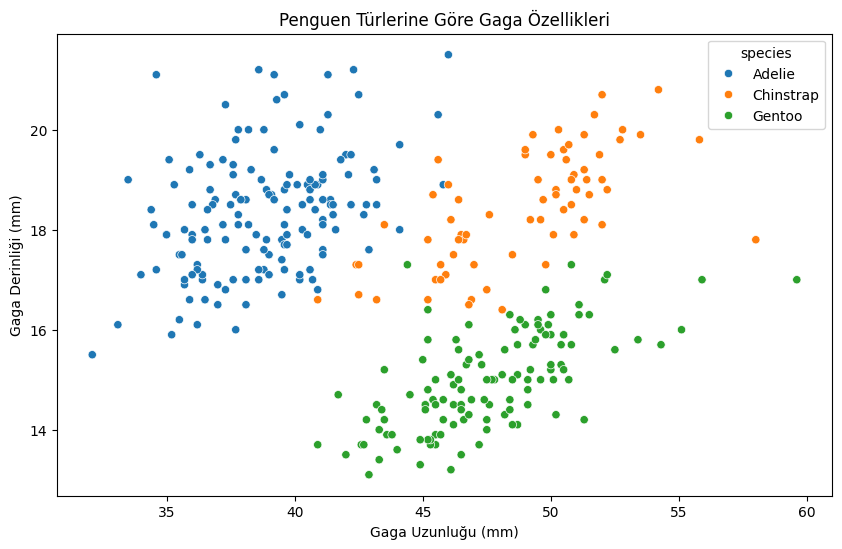

In [5]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=penguin_df,
    x="bill_length_mm",
    y="bill_depth_mm",
    hue="species"
)

plt.title("Penguen Türlerine Göre Gaga Özellikleri")
plt.xlabel("Gaga Uzunluğu (mm)")
plt.ylabel("Gaga Derinliği (mm)")
plt.show()

❓Gözlemlerinize dayanarak bu türleri ayırt edebiliyor musunuz?

Evet, penguen türleri gaga uzunluğu ve derinliği bakımından büyük ölçüde ayrışmaktadır. Adelie türü kısa ve derin gagalarıyla, Chinstrap uzun ve derin gagalarıyla, Gentoo ise uzun ve daha sığ gagalarıyla öne çıkmaktadır. Ancak bazı gözlemler örtüştüğü için bu iki özellik tek başına kusursuz sınıflandırma sağlamayabilir.

**gentoo** türü, diğer 2 türe göre açıkça daha uzun yüzgeçlere sahip gibi görünüyor.

## Modelleme

Çoklu sınıf sorununu çözmek için iki strateji vardır:

- Bire bir (One vs One)
- Bire tüm (Bire geri kalan)(One vs All)


### One vs One
- Dataset içindeki **her bir sınıf çifti için bir model** eğitilir
- Tahmin aşamasında, **en fazla oyu alan sınıf** seçilir

<img src='images/ovo_multiclass.png' width=500 style='margin:auto'> 


👍 Sınıf çiftlerine özgü farkları dikkate alır


👎 Çok sayıda alt model oluşturur: hesaplama açısından maliyetlidir


### One vs Rest (One vs All)

- **Her bir sınıf için**, diğer tüm sınıflara karşı **tek bir model** eğitilir
- Tahmin aşamasında, **en yüksek olasılığa sahip sınıf** seçilir

<img src='images/ova_multiclass.png' width=500 style='margin:auto'> 

👍 Hesaplama açısından daha az maliyetlidir


👎 Sınıfların bir araya getirilmesiyle, sınıf çiftlerine özgü farklar kaybolur ve etkileri azalır

## One vs Rest

👇 Penguen türünü **sayısal (numerical)** feature’lara göre tahmin eden bir modeli değerlendirin. scikit-learn içinde, temel model olarak LogisticRegression kullanan bir One vs Rest multi-class classification uygulamak için doğru classifier’ı bulun. Modeli cross-validation ile değerlendirin ve bunun ne kadar süre aldığını kaydedin.

In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier
from sklearn.model_selection import cross_validate
import numpy as np
import time

# Sayısal özellikleri ve hedef değişkeni belirleyelim
X = penguin_df.select_dtypes(include="number")
y = penguin_df["species"]

# One vs Rest modelimizi oluşturalım
ovr_model = OneVsRestClassifier(
    LogisticRegression(max_iter=2000)
)

# Eğitim ve doğrulama süresini ölçelim
start_time = time.time()

ovr_results = cross_validate(
    ovr_model,
    X,
    y,
    cv=5,
    scoring="accuracy"
)

ovr_time = time.time() - start_time

# Ortalama doğruluk skorunu hesaplayalım
ovr_accuracy = ovr_results["test_score"].mean()

print("OvR Accuracy:", ovr_accuracy)
print("OvR Süre:", ovr_time, "saniye")

OvR Accuracy: 0.9880144730891001
OvR Süre: 0.28173232078552246 saniye


## One vs One

👇 Bu sefer bir `OneVsOneClassifier` implement edin.

Yine cross-validation ile değerlendirin ve bunun ne kadar süre aldığını kaydedin.

In [8]:
from sklearn.multiclass import OneVsOneClassifier

# One vs One modelini oluşturalım
ovo_model = OneVsOneClassifier(
    LogisticRegression(max_iter=2000)
)

# Süreyi ölçelim
start_time = time.time()

ovo_results = cross_validate(
    ovo_model,
    X,
    y,
    cv=5,
    scoring="accuracy"
)

ovo_time = time.time() - start_time

# Ortalama doğruluk
ovo_accuracy = ovo_results["test_score"].mean()

print("OvO Accuracy:", ovo_accuracy)
print("OvO Süre:", ovo_time, "saniye")

OvO Accuracy: 0.9850746268656717
OvO Süre: 0.20041584968566895 saniye


ℹ️ Her iki modelin de çok benzer doğruluklara sahip olduğunu görüyoruz. Neden? <br><br>
Öncelikle, her iki model de sınıflandırması görece kolay olan bir dataset üzerinde oldukça iyi bir performans sergiliyor. İkinci olarak, ayırt edilmesi gereken yalnızca üç sınıf olduğunda, hem OvO hem de OvR yaklaşımları aslında **3 adet alt modelin** eğitilmesiyle sonuçlanır! Bu nedenle, çok benzer doğruluklar elde etmemiz beklenir.

❓ Zoolog, 10 denemenin 9’unda doğru türü bulabiliyor; siz onu geçebilir misiniz?

<details>
<summary> 👉Çözüm </summary>
Yaklaşık %98’lik bir ortalama doğruluk elde etmelisiniz; bu da %90’dan daha yüksektir. Yani algoritmamız zoologu geçiyor!

</details>

# 🏁 